In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("insurance.csv")

In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [10]:
print('Missing Values per column: \n',df.isnull().sum())

Missing Values per column: 
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [11]:
print("Duplicate Rows Count: ", df.duplicated().sum())

Duplicate Rows Count:  1


In [12]:
df = df.drop_duplicates()
print(df.describe())

               age          bmi     children       charges
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.663452     1.095737  13279.121487
std      14.044333     6.100468     1.205571  12110.359656
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.290000     0.000000   4746.344000
50%      39.000000    30.400000     1.000000   9386.161300
75%      51.000000    34.700000     2.000000  16657.717450
max      64.000000    53.130000     5.000000  63770.428010


# Distrubution of the target variable

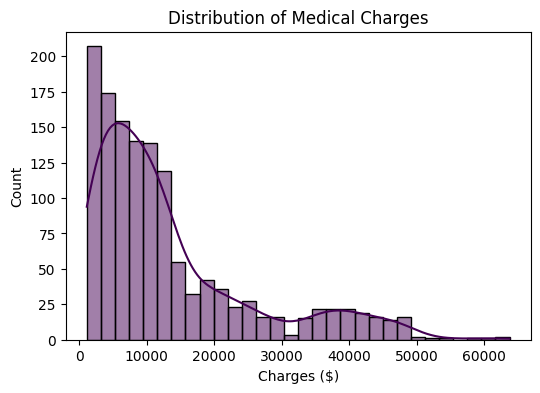

In [16]:
plt.figure(figsize=(6, 4))
sns.histplot(df['charges'], kde=True, bins=30, color='#440154')
plt.title("Distribution of Medical Charges")
plt.xlabel("Charges ($)")
plt.show()

# 2. Comparing smokers vs. non-smokers against charges

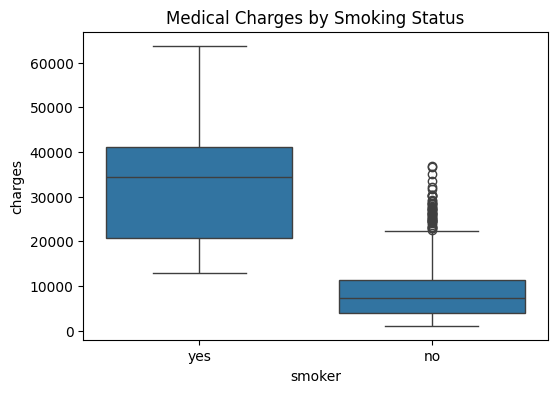

In [17]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='smoker', y='charges', data=df)
plt.title("Medical Charges by Smoking Status")
plt.show()

# 3. Age vs. Charges (colored by smoking status)

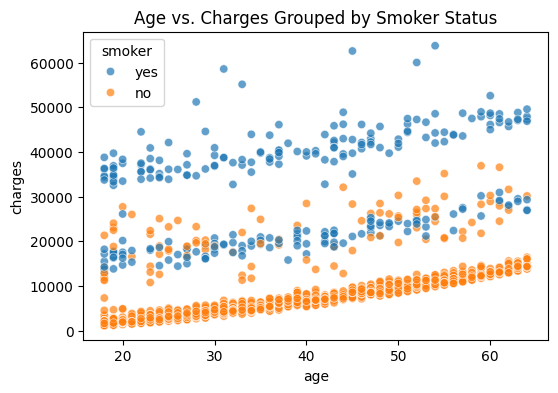

In [18]:
plt.figure(figsize=(6, 4))
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, alpha=0.7)
plt.title("Age vs. Charges Grouped by Smoker Status")
plt.show()

In [19]:
df_encoded = pd.get_dummies(df, drop_first=True)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")

Training samples: 1069, Testing samples: 268


In [22]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [23]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"R-squared Score (R2): {r2:.4f}")

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Weight ($)': model.coef_
}).sort_values(by='Weight ($)', ascending=False)

print("\nImpact of Each Feature on Predicted Charges:")
print(coefficients)

Mean Absolute Error (MAE): $4177.05
Root Mean Squared Error (RMSE): $5956.34
R-squared Score (R2): 0.8069

Impact of Each Feature on Predicted Charges:
            Feature    Weight ($)
4        smoker_yes  23077.764593
2          children    533.009989
1               bmi    318.701441
0               age    248.210720
3          sex_male   -101.542054
5  region_northwest   -391.761455
7  region_southwest   -659.139752
6  region_southeast   -838.919616


In [24]:
from sklearn.metrics import r2_score, mean_absolute_percentage_error
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print(f"Training Score (R²): {train_r2 * 100:.2f}%")
print(f"Testing Score (R²):  {test_r2 * 100:.2f}%")

mape = mean_absolute_percentage_error(y_test, y_pred)
approx_accuracy = (1 - mape) * 100

print(f"Mean Absolute Percentage Error (MAPE): {mape * 100:.2f}%")
print(f"Approximate Real-World Accuracy:       {approx_accuracy:.2f}%")

Training Score (R²): 72.99%
Testing Score (R²):  80.69%
Mean Absolute Percentage Error (MAPE): 41.40%
Approximate Real-World Accuracy:       58.60%


In [25]:
import joblib
model_package = {
    'model': model,
    'features': list(X_train.columns)
}

joblib.dump(model_package, 'insurance_charge_predictor.joblib')
print("Model successfully saved as 'insurance_charge_predictor.joblib'")

Model successfully saved as 'insurance_charge_predictor.joblib'


In [26]:
import joblib
import pandas as pd

saved_package = joblib.load('insurance_charge_predictor.joblib')
deployed_model = saved_package['model']
expected_features = saved_package['features']

new_customer_raw = pd.DataFrame([{
    'age': 35,
    'bmi': 28.5,
    'children': 2,
    'sex_male': 1,
    'smoker_yes': 1,
    'region_northwest': 0,
    'region_southeast': 0,
    'region_southwest': 0
}])

new_customer = new_customer_raw.reindex(columns=expected_features, fill_value=0)
predicted_cost = deployed_model.predict(new_customer)[0]
print(f"Estimated Medical Charge: ${predicted_cost:,.2f}")

Estimated Medical Charge: $30,719.96


In [27]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import xgboost as xgb

df = pd.read_csv('insurance.csv').drop_duplicates()
df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [28]:
xgb_model = xgb.XGBRegressor(random_state=42, objective='reg:squarederror')
param_distributions = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],          
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],   
    'reg_alpha': [0, 0.1, 1.0, 5.0],            
    'reg_lambda': [1.0, 2.0, 5.0, 10.0]        
}

cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=50,
    scoring='r2',
    cv=cv_strategy,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best Parameters Found:")
for param, val in search.best_params_.items():
    print(f"  {param}: {val}")
print(f"\nBest 5-Fold Cross-Validation R² Score: {search.best_score_:.4f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters Found:
  subsample: 0.9
  reg_lambda: 5.0
  reg_alpha: 1.0
  n_estimators: 200
  max_depth: 3
  learning_rate: 0.03
  colsample_bytree: 1.0

Best 5-Fold Cross-Validation R² Score: 0.8463


In [29]:
best_xgb = search.best_estimator_
y_pred = best_xgb.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = mean_absolute_percentage_error(y_test, y_pred)
accuracy_pct = (1 - mape) * 100

print(f"Test R² Score:                        {r2:.4f} ({r2 * 100:.2f}%)")
print(f"Mean Absolute Error (MAE):            ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE):       ${rmse:,.2f}")
print(f"Mean Absolute Percentage Error (MAPE):{mape * 100:.2f}%")
print(f"Approximate Real-World Accuracy:      {accuracy_pct:.2f}%")

Test R² Score:                        0.9033 (90.33%)
Mean Absolute Error (MAE):            $2,455.57
Root Mean Squared Error (RMSE):       $4,215.60
Mean Absolute Percentage Error (MAPE):31.14%
Approximate Real-World Accuracy:      68.86%


In [30]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_xgb.feature_importances_
}).sort_values(by='Importance', ascending=False)
print("\nFeature Importance Breakdown:")
print(importance_df)


Feature Importance Breakdown:
            Feature  Importance
4        smoker_yes    0.841217
1               bmi    0.078318
0               age    0.044212
2          children    0.010994
5  region_northwest    0.006879
3          sex_male    0.006470
6  region_southeast    0.006028
7  region_southwest    0.005881


In [31]:
bundle = {
    'model': best_xgb,
    'features': list(X_train.columns),
    'model_type': 'XGBoost Regressor'
}

joblib.dump(bundle, 'tuned_xgboost_insurance_model.joblib')
print("Model saved to 'tuned_xgboost_insurance_model.joblib'")

loaded_bundle = joblib.load('tuned_xgboost_insurance_model.joblib')
deployed_model = loaded_bundle['model']
expected_cols = loaded_bundle['features']

sample_client = pd.DataFrame([{
    'age': 45,
    'bmi': 31.2,
    'children': 1,
    'sex_male': 1,
    'smoker_yes': 1,
    'region_northwest': 1,
    'region_southeast': 0,
    'region_southwest': 0
}]).reindex(columns=expected_cols, fill_value=0)

prediction = deployed_model.predict(sample_client)[0]
print(f"Predicted Medical Cost for New Client: ${prediction:,.2f}")

Model saved to 'tuned_xgboost_insurance_model.joblib'
Predicted Medical Cost for New Client: $42,205.77


In [32]:
non_smoker_client = sample_client.copy()
non_smoker_client['smoker_yes'] = 0

non_smoker_prediction = deployed_model.predict(non_smoker_client)[0]

print(f"Smoker Premium:     ${prediction:,.2f}")
print(f"Non-Smoker Premium: ${non_smoker_prediction:,.2f}")
print(f"Smoker Surcharge:   ${prediction - non_smoker_prediction:,.2f}")

Smoker Premium:     $42,205.77
Non-Smoker Premium: $8,870.90
Smoker Surcharge:   $33,334.87


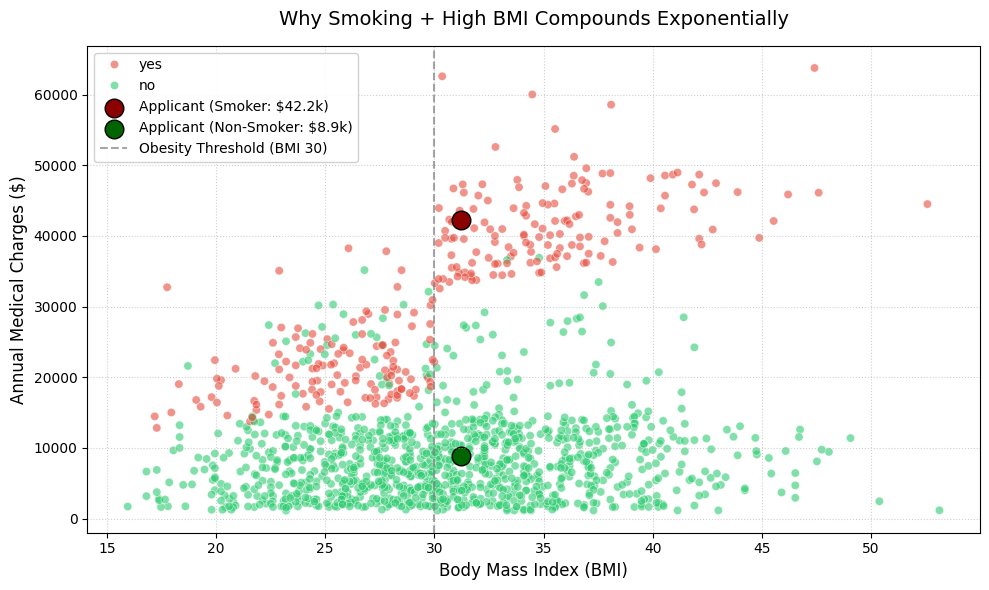

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df, 
    x='bmi', 
    y='charges', 
    hue='smoker', 
    alpha=0.6, 
    palette={'yes': '#e74c3c', 'no': '#2ecc71'}
)

plt.scatter([31.2], [42205.77], color='darkred', s=180, edgecolors='black', label='Applicant (Smoker: $42.2k)')
plt.scatter([31.2], [8870.90], color='darkgreen', s=180, edgecolors='black', label='Applicant (Non-Smoker: $8.9k)')

plt.axvline(30, color='gray', linestyle='--', alpha=0.7, label='Obesity Threshold (BMI 30)')

plt.title("Why Smoking + High BMI Compounds Exponentially", fontsize=14, pad=15)
plt.xlabel("Body Mass Index (BMI)", fontsize=12)
plt.ylabel("Annual Medical Charges ($)", fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()